In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"

df = pd.read_csv(REPORTS_DIR / "dataset_audit.csv")

print("Total images:", len(df))
print(df["folder"].value_counts())

Total images: 1060
folder
homogeneous      696
imgs             200
inhomogeneous    164
Name: count, dtype: int64


##Class Distribution

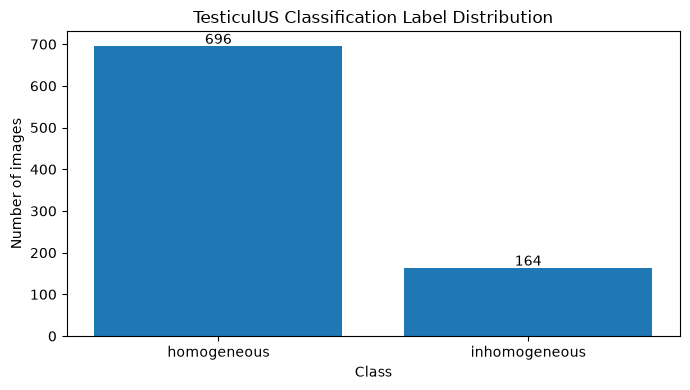

In [2]:
classification_df = df[df["label"].notna()].copy()

class_counts = (
    classification_df["folder"]
    .value_counts()
    .reindex(["homogeneous", "inhomogeneous"])
)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    class_counts.index,
    class_counts.values
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(int(bar.get_height())),
        ha="center"
    )

ax.set_title("TesticulUS Classification Label Distribution")
ax.set_ylabel("Number of images")
ax.set_xlabel("Class")

plt.tight_layout()
plt.show()